# Pairwise Difference Learning: 2nd of 11 on TabMini

**On 44 small binary datasets (32 to 500 rows), with every model at its default settings, PDL ranks 2nd of 11 classifiers by mean rank of per-dataset ROC AUC: behind CatBoost, ahead of the other nine, random forest, XGBoost and LightGBM included.** It is in the top 3 on 23 of the 44 datasets, more often than any other model (CatBoost: 22). This is a placing, not a win: PDL's differences from CatBoost, random forest, extra trees, SVM, logistic regression and XGBoost are not statistically significant (see below).

Many real projects start with a small table: a few hundred rows, a binary label, no time to tune. This notebook runs the [TabMini](https://github.com/RicardoKnauer/TabMini) benchmark ([Knauer et al. 2024](https://arxiv.org/abs/2409.01635)) with its own protocol.

*Runs on Kaggle with Internet on: the first cell installs `pdll` from PyPI, and the 44 datasets are read from PMLB on GitHub.*

**Pairwise Difference Learning (PDL)** trains a model on *pairs* of rows: "do these two rows have the same label?" (or, for regression, "how far apart are their targets?"). A new row is then compared with the training rows, whose labels are known, and the answers are combined. With n training rows the model can learn from up to n² pairs, which is why it is aimed at small tables. [`pdll`](https://github.com/Karim-53/pdll) wraps any scikit-learn model with the usual `fit` / `predict` API. Method: [Belaid, Rabus & Hüllermeier, *Pairwise Difference Learning for Classification*, Discovery Science 2024](https://doi.org/10.1007/978-3-031-78980-9_18). *Disclosure: I am one of the authors.*

In [ ]:
!pip install -q pdll==1.0.0 scikit-learn==1.9.1 catboost==1.2.10 lightgbm==4.7.0 xgboost==3.4.1

In [2]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare, rankdata, wilcoxon
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

import pdll
from pdll import PairwiseDifferenceClassifier

warnings.simplefilter('ignore')
N_JOBS = os.cpu_count()
import catboost, lightgbm, sklearn, xgboost
print('pdll', pdll.__version__, '| scikit-learn', sklearn.__version__, '| catboost', catboost.__version__,
      '| lightgbm', lightgbm.__version__, '| xgboost', xgboost.__version__)

pdll 1.0.0 | scikit-learn 1.9.1 | catboost 1.2.10 | lightgbm 4.7.0 | xgboost 3.4.1


## The data: TabMini, exactly as published

TabMini reads each dataset from [PMLB](https://github.com/EpistasisLab/pmlb), drops rows with missing values, shuffles the rows with seed 42 and takes the largest label as the positive class. We read the files from the PMLB commit TabMini used (9 datasets were renamed later). All features are numeric.

In [3]:
DATASETS = [
    'parity5', 'analcatdata_fraud', 'analcatdata_aids', 'analcatdata_bankruptcy', 'analcatdata_japansolvent', 'labor',
    'analcatdata_asbestos', 'lupus', 'postoperative_patient_data', 'analcatdata_cyyoung9302', 'analcatdata_cyyoung8092',
    'analcatdata_creditscore', 'appendicitis', 'molecular_biology_promoters', 'analcatdata_boxing1', 'mux6',
    'analcatdata_boxing2', 'hepatitis', 'corral', 'glass2', 'backache', 'prnn_crabs', 'sonar', 'biomed', 'prnn_synth',
    'analcatdata_lawsuit', 'spect', 'heart_statlog', 'breast_cancer', 'heart_h', 'hungarian', 'cleve', 'heart_c',
    'haberman', 'bupa', 'spectf', 'ionosphere', 'colic', 'horse_colic', 'house_votes_84', 'vote', 'saheart', 'clean1', 'irish',
]
PMLB = 'https://github.com/EpistasisLab/pmlb/raw/872ec0a1f99ca0b55a8c8c5491da09a7da66ce13/datasets/{0}/{0}.tsv.gz'


def load(name):
    frame = pd.read_csv(PMLB.format(name), sep='\t', compression='gzip').dropna()
    frame = frame.sample(frac=1, random_state=42).reset_index(drop=True)
    return frame.drop(columns='target'), (frame['target'] == frame['target'].max()).astype(int).to_numpy()


data = {name: load(name) for name in DATASETS}
sizes = pd.Series({name: len(y) for name, (X, y) in data.items()})
print(f'{len(data)} datasets, {sizes.min()} to {sizes.max()} rows (median {int(sizes.median())})')

44 datasets, 32 to 500 rows (median 204)


## The 11 classifiers, all at their defaults

Only `random_state=0`, the thread count, `max_iter=1000` for logistic regression (the default often stops before converging) and `probability=True` for the SVM (to get probabilities) are set. Linear, k-NN and SVM models get standardized features. PDL is `PairwiseDifferenceClassifier(random_state=0)`: its default base model is an extra-trees forest with `class_weight='balanced'`.

In [4]:
def scaled(model):
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), model)


MODELS = {
    'PDL (pdll)': lambda: PairwiseDifferenceClassifier(random_state=0),
    'CatBoost': lambda: CatBoostClassifier(random_seed=0, thread_count=N_JOBS, verbose=0, allow_writing_files=False),
    'Random forest': lambda: RandomForestClassifier(random_state=0, n_jobs=N_JOBS),
    'Extra trees': lambda: ExtraTreesClassifier(random_state=0, n_jobs=N_JOBS),
    'SVM (RBF)': lambda: scaled(SVC(probability=True, random_state=0)),
    'Logistic regression': lambda: scaled(LogisticRegression(max_iter=1000)),
    'XGBoost': lambda: XGBClassifier(random_state=0, n_jobs=N_JOBS),
    'LightGBM': lambda: LGBMClassifier(random_state=0, n_jobs=N_JOBS, verbose=-1),
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(random_state=0),
    'k-NN': lambda: scaled(KNeighborsClassifier(n_jobs=N_JOBS)),
    'Decision tree': lambda: DecisionTreeClassifier(random_state=0),
}

## Run: TabMini's protocol

Stratified 3-fold cross-validation on the shuffled rows, ROC AUC on each test fold, averaged over the 3 folds. This takes about 17 minutes on a 12-thread laptop and up to about an hour on Kaggle's 4 CPUs, CatBoost and PDL taking most of it.

In [5]:
auc = {}
for name, (X, y) in data.items():
    for model_name, make in MODELS.items():
        scores = []
        for train, test in StratifiedKFold(3).split(X, y):
            model = make().fit(X.iloc[train], y[train])
            scores.append(roc_auc_score(y[test], model.predict_proba(X.iloc[test])[:, 1]))
        auc[name, model_name] = np.mean(scores)
    print(name, end=', ', flush=True)
auc = pd.Series(auc).unstack()[list(MODELS)].round(5)   # 5 decimals, as in the benchmark repo's results
print(f'\n{auc.shape[0]} datasets x {auc.shape[1]} classifiers scored')

parity5, 

analcatdata_fraud, 

analcatdata_aids, 

analcatdata_bankruptcy, 

analcatdata_japansolvent, 

...

vote, 

saheart, 

clean1, 

irish, 


44 datasets x 11 classifiers scored


## Ranking

On each dataset the models are ranked by ROC AUC (1 = best, ties averaged); then the ranks are averaged over the 44 datasets.

In [6]:
ranks = auc.apply(lambda row: pd.Series(rankdata(-row.to_numpy(), method='average'), index=row.index), axis=1)
table = pd.DataFrame({'mean rank': ranks.mean(), 'mean ROC AUC': auc.mean(), 'top-3 finishes': (ranks <= 3).sum()})
table = table.sort_values('mean rank')
table.index.name = 'model'
table.round(3)

,mean rank,mean ROC AUC,top-3 finishes
model,,,
CatBoost,3.648,0.850,22
PDL (pdll),3.977,0.843,23
Random forest,4.591,0.839,11
Extra trees,5.080,0.835,13
SVM (RBF),5.148,0.850,15
Logistic regression,5.750,0.823,15
LightGBM,6.057,0.804,6
XGBoost,6.136,0.834,9
HistGradientBoosting,7.182,0.799,4


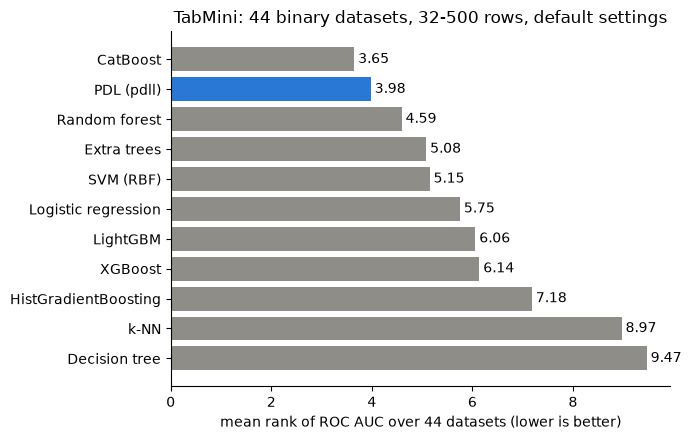

In [7]:
order = table.index[::-1]
colors = ['#2a78d6' if m == 'PDL (pdll)' else '#8f8d88' for m in order]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(order, table.loc[order, 'mean rank'], color=colors)
for i, m in enumerate(order):
    ax.text(table.loc[m, 'mean rank'] + 0.08, i, f"{table.loc[m, 'mean rank']:.2f}", va='center')
ax.set_xlabel('mean rank of ROC AUC over 44 datasets (lower is better)')
ax.set_title('TabMini: 44 binary datasets, 32-500 rows, default settings')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## Is the difference real?

A Friedman test checks that the models differ at all; then PDL is compared with each model by a Wilcoxon signed-rank test over the 44 datasets, Holm-corrected for 10 comparisons.

In [8]:
print('Friedman p =', f'{friedmanchisquare(*[auc[m] for m in auc.columns]).pvalue:.1e}')

others = [m for m in table.index if m != 'PDL (pdll)']
p_raw = np.array([wilcoxon(auc['PDL (pdll)'] - auc[m], zero_method='zsplit').pvalue for m in others])
order_p = np.argsort(p_raw)
p_holm = np.empty_like(p_raw)
p_holm[order_p] = np.maximum.accumulate(np.minimum(1, (len(p_raw) - np.arange(len(p_raw))) * p_raw[order_p]))
diff = auc[['PDL (pdll)']].to_numpy() - auc[others]
pd.DataFrame({'PDL wins': (diff > 0.005).sum(), 'ties (within 0.005)': (diff.abs() <= 0.005).sum(),
              'PDL losses': (diff < -0.005).sum(), 'mean AUC difference': diff.mean().round(4),
              'Holm p': [f'{p:.2g}' for p in p_holm]}, index=others)

Friedman p = 2.7e-26


,PDL wins,ties (within 0.005),PDL losses,mean AUC difference,Holm p
CatBoost,14,17,13,-0.0064,0.83
Random forest,24,13,7,0.0039,0.16
Extra trees,19,18,7,0.0083,0.068
SVM (RBF),23,10,11,-0.0067,0.17
Logistic regression,24,7,13,0.0204,0.17
LightGBM,28,9,7,0.0390,0.011
XGBoost,25,11,8,0.0095,0.076
HistGradientBoosting,31,6,7,0.0444,0.0019
k-NN,39,2,3,0.0477,2.1e-06
Decision tree,38,3,3,0.0997,3e-06


PDL's differences from CatBoost, random forest, extra trees, SVM, logistic regression and XGBoost are not statistically significant (CatBoost: Holm p = 0.83): on 44 small datasets the top group is close. By this test PDL is significantly better than LightGBM, HistGradientBoosting, k-NN and a single decision tree; part of the lead over LightGBM and HistGradientBoosting comes from the 6 smallest datasets, where their defaults cannot split (see Scope). Read the result as "a top-group model at default settings", not as "the winner".

## Robustness

Four pairs of TabMini datasets are the same UCI problem, and 14 datasets had been used while developing PDL (the paper and pdll's own tests). The benchmark repo also finds PDL 2nd on the 25 datasets TabMini now keeps, on the 23 outside TabPFN's prior and when any one or two datasets are left out, and in the top 3 in 98% of bootstrap resamples of the datasets. Here, the place holds without the duplicates and without the 14:

In [9]:
def pdl_place(names):
    means = ranks.loc[names].mean().sort_values()
    return list(means.index).index('PDL (pdll)') + 1, f"{means['PDL (pdll)']:.2f}", means.index[0]

views = {
    'all 44': DATASETS,
    '40 distinct (one of each duplicate pair)': [n for n in DATASETS if n not in {'house_votes_84', 'hungarian', 'heart_c', 'horse_colic'}],
    'the 30 PDL had never been run on': [n for n in DATASETS if n not in {
        'molecular_biology_promoters', 'mux6', 'analcatdata_boxing2', 'glass2', 'prnn_synth', 'spect', 'heart_statlog',
        'heart_h', 'hungarian', 'cleve', 'heart_c', 'haberman', 'spectf', 'ionosphere'}],
}
pd.DataFrame({view: pdl_place(names) for view, names in views.items()}, index=['PDL place', 'PDL mean rank', '1st']).T

,PDL place,PDL mean rank,1st
all 44,2,3.98,CatBoost
40 distinct (one of each duplicate pair),2,4.20,CatBoost
the 30 PDL had never been run on,2,4.02,CatBoost


## Scope

- Binary classification, at most 500 rows; one shuffle seed, 3 folds, one model seed; no model tuned.
- ROC AUC, binary targets and small data were chosen after an earlier benchmark (35 OpenML tasks with 500 to 2,000 rows), on which PDL did better by ROC AUC than by accuracy or macro-F1, and better on binary and smaller tasks. On TabMini, PDL is 3rd by accuracy too (benchmark repo; not computed here).
- By mean AUC instead of mean rank, PDL is 3rd.
- Default LightGBM and HistGradientBoosting cannot split on the 6 smallest datasets (at most 57 rows) and score 0.5 there, which accounts for part of PDL's lead over them.
- TabPFN and AutoML tools are not in this comparison.

Full harness, per-fold scores and checks: [pdll/benchmark/tabmini](https://github.com/Karim-53/pdll/tree/main/benchmark/tabmini).

## Try it on your own small table

In [10]:
from sklearn.model_selection import cross_val_score

X, y = data['sonar']   # your table here: a DataFrame (string columns are ordinal-encoded) or an array, and labels
model = PairwiseDifferenceClassifier(random_state=0)   # or wrap any classifier: PairwiseDifferenceClassifier(RandomForestClassifier(class_weight='balanced'))
print('ROC AUC', cross_val_score(model, X, y, cv=5, scoring='roc_auc').mean().round(3))

ROC AUC 0.946


If PDL is useful in your work, please cite the paper:

```bibtex
@inproceedings{belaid2024pairwise,
  title     = {Pairwise Difference Learning for Classification},
  author    = {Belaid, Mohamed Karim and Rabus, Maximilian and H{\"u}llermeier, Eyke},
  booktitle = {Discovery Science},
  pages     = {284--299},
  publisher = {Springer},
  year      = {2024},
  doi       = {10.1007/978-3-031-78980-9_18}
}
```